In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the project root
roots = [Path.cwd(), *Path.cwd().parents]

PROJECT_ROOT = next(
    (
        p for p in roots
        if (p / "data" / "features").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project data/features folder not found")

file = (
    PROJECT_ROOT / "data" / "features"
    / "brazil_serie_a_2025_prematch.csv"
)

df = pd.read_csv(file, parse_dates=["date"])

display(df.head(10))

,date,home_team,away_team,historical_matches,home_attack_strength,away_defence_weakness,away_attack_strength,home_defence_weakness,lambda_home,lambda_away,actual_home_goals,actual_away_goals
0,2025-04-26,SC Internacional,EC Juventude,50,0.9926,1.4564,0.7143,0.8929,2.2262,0.5102,3,1
1,2025-04-26,Mirassol FC,CA Mineiro,50,1.1781,1.0853,0.8929,1.0714,1.9691,0.7653,2,2
2,2025-04-26,Ceará SC,São Paulo FC,50,1.0853,0.8998,1.0714,0.8929,1.5040,0.7653,1,1
3,2025-04-26,SC Recife,Fortaleza EC,50,0.8071,0.9926,1.0714,1.2500,1.2336,1.0714,0,0
4,2025-04-26,Botafogo FR,Fluminense FC,50,1.0853,0.8998,1.0714,1.0714,1.5040,0.9184,2,0
5,2025-04-27,Santos FC,RB Bragantino,55,1.0840,0.8992,1.0714,1.0714,1.5064,0.9184,1,2
6,2025-04-27,Cruzeiro EC,CR Vasco da Gama,55,1.1765,1.1765,0.8929,0.8929,2.1390,0.6378,1,0
7,2025-04-27,EC Vitória,Grêmio FBPA,55,0.9916,1.2689,0.8929,1.2500,1.9446,0.8929,1,1
8,2025-04-27,CR Flamengo,SC Corinthians Paulista,55,1.3613,0.9916,0.8929,0.8929,2.0862,0.6378,4,0
9,2025-04-27,SE Palmeiras,EC Bahia,55,0.8992,1.1765,1.0714,0.7143,1.6348,0.6122,0,1


In [3]:
df.info()
display(df.describe().round(2))
display(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 330 entries, 0 to 329
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   330 non-null    datetime64[us]
 1   home_team              330 non-null    str           
 2   away_team              330 non-null    str           
 3   historical_matches     330 non-null    int64         
 4   home_attack_strength   330 non-null    float64       
 5   away_defence_weakness  330 non-null    float64       
 6   away_attack_strength   330 non-null    float64       
 7   home_defence_weakness  330 non-null    float64       
 8   lambda_home            330 non-null    float64       
 9   lambda_away            330 non-null    float64       
 10  actual_home_goals      330 non-null    int64         
 11  actual_away_goals      330 non-null    int64         
dtypes: datetime64[us](1), float64(6), int64(3), str(2)
memory usage: 31.1 KB


,date,historical_matches,home_attack_strength,away_defence_weakness,away_attack_strength,home_defence_weakness,lambda_home,lambda_away,actual_home_goals,actual_away_goals
count,330,330.00,330.00,330.00,330.00,330.00,330.00,330.00,330.00,330.00
mean,2025-08-31 18:06:32.727272,212.69,1.00,1.00,1.00,1.00,1.45,0.92,1.52,1.03
min,2025-04-26 00:00:00,50.00,0.59,0.51,0.50,0.44,0.53,0.30,0.00,0.00
25%,2025-07-19 00:00:00,130.00,0.86,0.86,0.85,0.87,1.13,0.72,1.00,0.00
50%,2025-09-14 00:00:00,213.00,0.95,1.00,1.00,0.98,1.39,0.88,1.00,1.00
75%,2025-10-31 06:00:00,296.75,1.12,1.14,1.12,1.13,1.69,1.09,2.00,2.00
max,2025-12-07 00:00:00,371.00,1.68,1.89,1.55,1.75,3.39,2.10,8.00,6.00
std,NaN,95.39,0.21,0.24,0.22,0.21,0.45,0.29,1.28,1.06


date                     0
home_team                0
away_team                0
historical_matches       0
home_attack_strength     0
away_defence_weakness    0
away_attack_strength     0
home_defence_weakness    0
lambda_home              0
lambda_away              0
actual_home_goals        0
actual_away_goals        0
dtype: int64

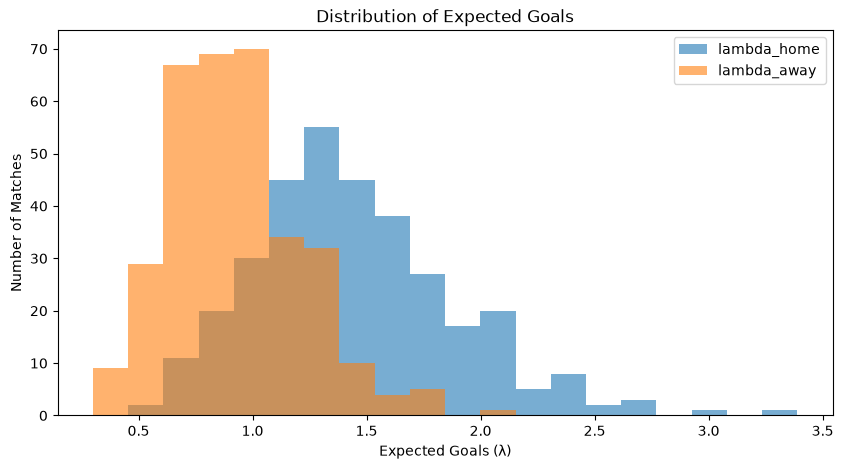

In [4]:
ax = df[["lambda_home", "lambda_away"]].plot.hist(
    bins=20,
    alpha=0.6,
    figsize=(10, 5)
)

ax.set_title("Distribution of Expected Goals")
ax.set_xlabel("Expected Goals (λ)")
ax.set_ylabel("Number of Matches")

plt.show()

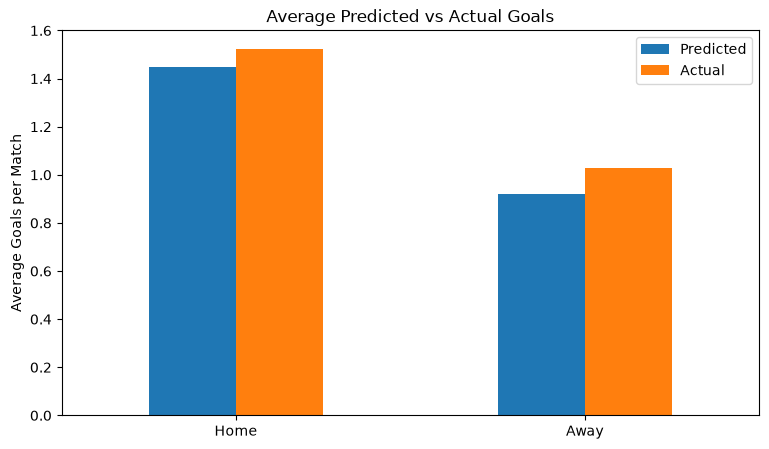

In [5]:
comparison = pd.DataFrame(
    {
        "Predicted": [
            df["lambda_home"].mean(),
            df["lambda_away"].mean()
        ],
        "Actual": [
            df["actual_home_goals"].mean(),
            df["actual_away_goals"].mean()
        ]
    },
    index=["Home", "Away"]
)

ax = comparison.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Average Predicted vs Actual Goals")
ax.set_ylabel("Average Goals per Match")

plt.show()

In [ ]:
# Start with the first available home team.
# Replace with another exact team name if desired.
team = df["home_team"].iloc[0]

team_df = df[
    df["home_team"] == team
].sort_values("date")

plt.figure(figsize=(12, 5))

plt.plot(
    team_df["date"],
    team_df["lambda_home"],
    marker="o",
    label="Expected Goals"
)

plt.scatter(
    team_df["date"],
    team_df["actual_home_goals"],
    label="Actual Goals",
    s=65
)

plt.title(f"{team} — Home Match Performance")
plt.xlabel("Match Date")
plt.ylabel("Goals")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

NameError: name 'df' is not defined